## Attempt 1

In [1]:
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt

In [2]:
# Load the background-only TIFF files to analyze their pixel intensities
background_file_paths = [
    'sample_1_cs_4_2/0787.tiff',
    'sample_1_cs_4_2/0788.tiff',
    'sample_1_cs_4_2/0789.tiff',
    'sample_1_cs_4_2/0790.tiff',
    'sample_1_cs_4_2/0791.tiff',
    'sample_1_cs_4_2/0792.tiff',
    'sample_1_cs_4_2/0793.tiff',
    'sample_1_cs_4_2/0794.tiff',
    'sample_1_cs_4_2/0795.tiff',
    'sample_1_cs_4_2/0796.tiff'
]

# Load and stack background images
background_images = [tifffile.imread(file_path) for file_path in background_file_paths]
background_stack = np.stack(background_images, axis=0)

# Calculate the mean and standard deviation for the background pixel intensities
background_mean = background_stack.mean()
background_std = background_stack.std()
background_interval = (background_mean - 2 * background_std, background_mean + 2 * background_std)

background_mean, background_std, background_interval


(28137.577483731067,
 15683.243723706257,
 (-3228.9099636814462, 59504.064931143585))

Background mean: 28114.101601341208
Background tolerance interval: (15114.101601341208, 41114.10160134121)


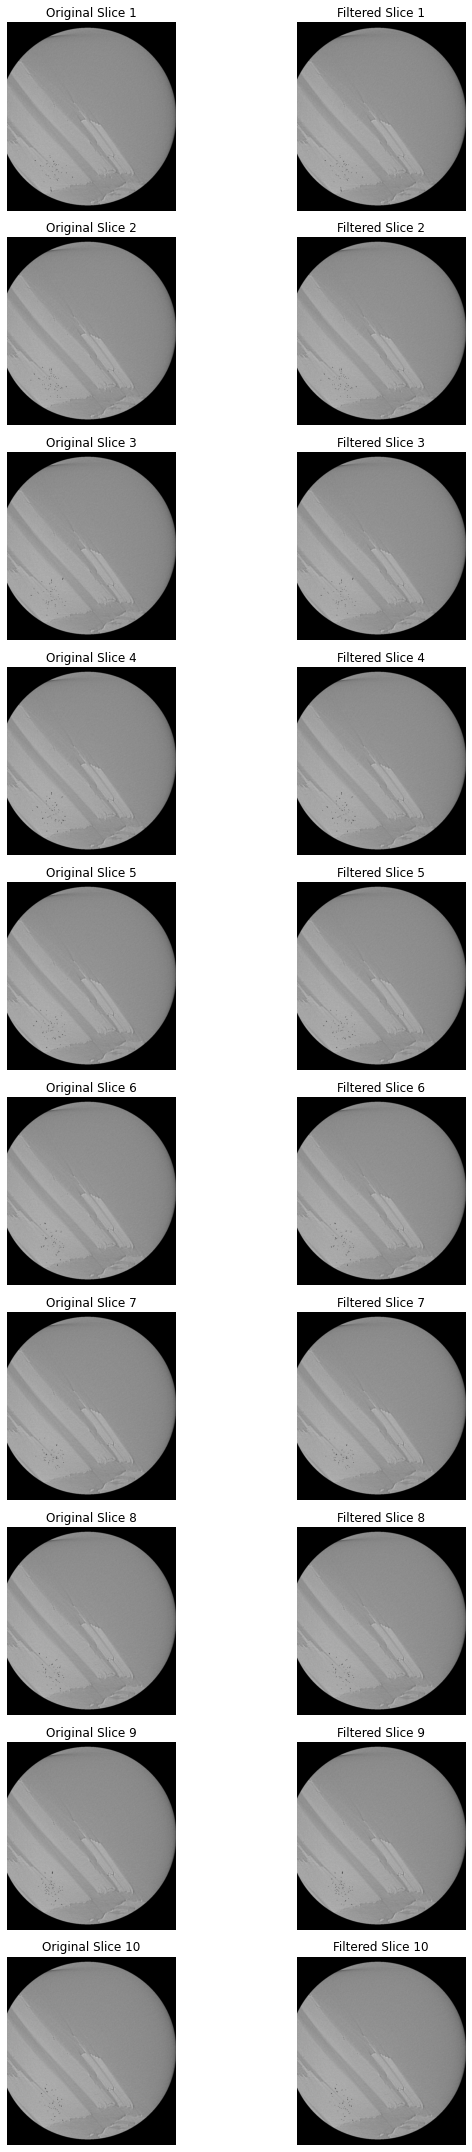

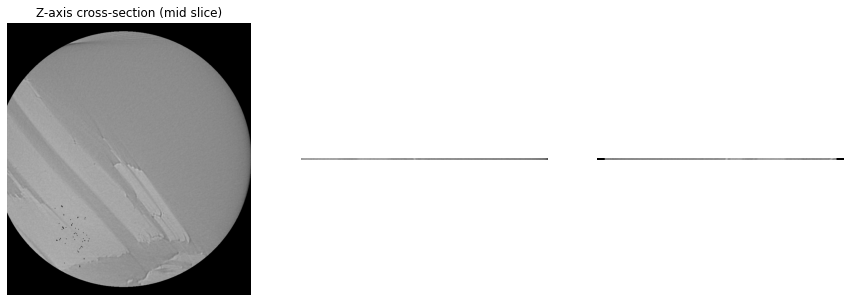

In [3]:
# Step 1: Load background-only TIFF files to calculate intensity statistics
def load_background_tiff_files(background_folder_path):
    tiff_files = sorted([os.path.join(background_folder_path, f) for f in os.listdir(background_folder_path) if f.endswith('.tiff')])
    background_images = [tifffile.imread(file) for file in tiff_files]
    background_stack = np.stack(background_images, axis=0)
    return background_stack

# Step 2: Calculate background intensity tolerance range from background images
def calculate_background_tolerance(background_stack, tolerance=3000):
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 3: Load the first 10-15 TIFF files with rock remnants
def load_first_tiff_files(folder_path, num_files=15):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])[:num_files]
    image_stack = [tifffile.imread(file) for file in tiff_files]
    return np.stack(image_stack, axis=0)

# Step 4: Apply background tolerance filtering based on calculated tolerance interval
def apply_tolerance_filter(image_stack, tolerance_interval):
    filtered_stack = np.zeros_like(image_stack)
    lower, upper = tolerance_interval
    for i in range(image_stack.shape[0]):
        # Keep pixels that fall outside the tolerance interval
        filtered_stack[i] = np.where((image_stack[i] < lower) | (image_stack[i] > upper), image_stack[i], 0)
    return filtered_stack

# Step 5: Display original and filtered images side by side for comparison
def display_comparison(original_stack, filtered_stack):
    num_slices = original_stack.shape[0]
    fig, axes = plt.subplots(num_slices, 2, figsize=(10, 3 * num_slices))
    
    for i in range(num_slices):
        axes[i, 0].imshow(original_stack[i], cmap="gray")
        axes[i, 0].set_title(f"Original Slice {i+1}")
        axes[i, 0].axis("off")
        
        axes[i, 1].imshow(filtered_stack[i], cmap="gray")
        axes[i, 1].set_title(f"Filtered Slice {i+1}")
        axes[i, 1].axis("off")
    
    plt.tight_layout()
    plt.show()

# Step 6: 3D Stack Visualization of Filtered Slices
def visualize_3d_stack(binary_stack):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    mid_z = binary_stack.shape[0] // 2
    mid_y = binary_stack.shape[1] // 2
    mid_x = binary_stack.shape[2] // 2
    
    axes[0].imshow(binary_stack[mid_z, :, :], cmap="gray")
    axes[0].set_title("Z-axis cross-section (mid slice)")
    
    axes[1].imshow(binary_stack[:, mid_y, :], cmap="gray")
    axes[2].imshow(binary_stack[:, :, mid_x], cmap="gray")
    
    for ax in axes:
        ax.axis("off")
    
    plt.show()

# Main Script
background_folder_path = "background_only" 
rock_folder_path = "SamplesWTracks"  

# Load background images and calculate the tolerance interval
background_stack = load_background_tiff_files(background_folder_path)
tolerance_interval = calculate_background_tolerance(background_stack, tolerance=13000)

# Load images with rock remnants
image_stack = load_first_tiff_files(rock_folder_path, num_files=10)  #fewer images for testing

# Apply tolerance filter
filtered_stack = apply_tolerance_filter(image_stack, tolerance_interval)

# Display original and filtered images side-by-side
display_comparison(image_stack, filtered_stack)

# Visualize the 3D stack of filtered slices
visualize_3d_stack(filtered_stack)


Background mean: 28114.101601341208
Background tolerance interval: (15114.101601341208, 41114.10160134121)


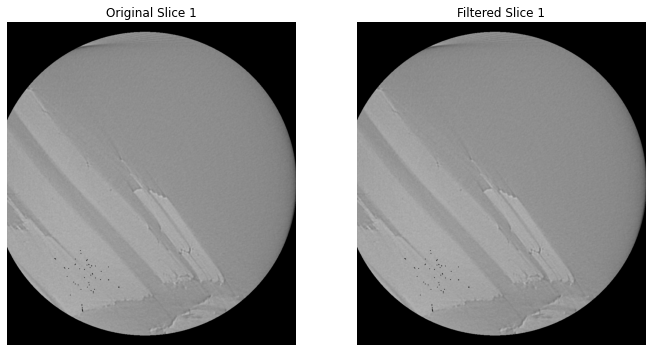

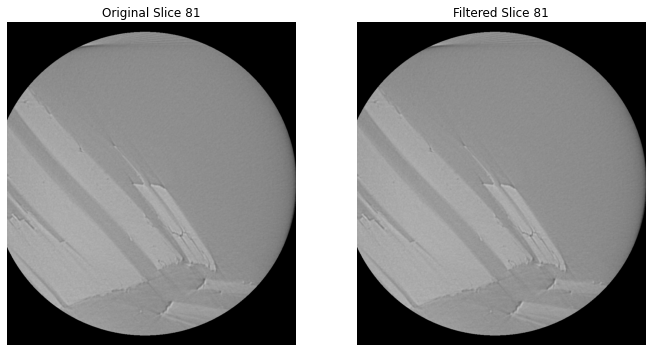

In [6]:
# Step 1: Load background-only TIFF files to calculate intensity statistics
def load_background_tiff_files(background_folder_path):
    tiff_files = sorted([os.path.join(background_folder_path, f) for f in os.listdir(background_folder_path) if f.endswith('.tiff')])
    background_images = [tifffile.imread(file) for file in tiff_files]
    background_stack = np.stack(background_images, axis=0)
    return background_stack

# Step 2: Calculate background intensity tolerance range from background images
def calculate_background_tolerance(background_stack, tolerance=3000):
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 4: Process images one by one, apply background tolerance filtering, and save the filtered images
def process_and_save_images(rock_folder_path, tolerance_interval, output_folder_path, display_every=80):
    tiff_files = sorted([os.path.join(rock_folder_path, f) for f in os.listdir(rock_folder_path) if f.endswith('.tiff')])
    if not os.path.exists(output_folder_path):
        os.makedirs(output_folder_path)
    
    for i, file_path in enumerate(tiff_files):
        # Load the image
        image = tifffile.imread(file_path)
        # Apply tolerance filter
        lower, upper = tolerance_interval
        filtered_image = np.where((image < lower) | (image > upper), image, 0)
        # Save the filtered image
        output_file = os.path.join(output_folder_path, f"filtered_{i+1:04d}.tiff")
        tifffile.imwrite(output_file, filtered_image.astype(np.uint16))
        # Display every 80th image
        if (i % display_every) == 0:
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(image, cmap="gray")
            axes[0].set_title(f"Original Slice {i+1}")
            axes[0].axis("off")
            axes[1].imshow(filtered_image, cmap="gray")
            axes[1].set_title(f"Filtered Slice {i+1}")
            axes[1].axis("off")
            plt.tight_layout()
            plt.show()

# Main Script
background_folder_path = "background_only"  
rock_folder_path = "SamplesWTracks"       
output_folder_path = "thresholded_samples_wtracks"      # Directory to save filtered images

# Load background images and calculate the tolerance interval
background_stack = load_background_tiff_files(background_folder_path)
tolerance_interval = calculate_background_tolerance(background_stack, tolerance=13000)

# Process images one by one, apply filter, and save them
process_and_save_images(rock_folder_path, tolerance_interval, output_folder_path, display_every=80)


In [23]:
import pyvista as pv
pv.start_xvfb()  # Starts a virtual display

In [ ]:
# Step 1: Load background-only TIFF files to calculate intensity statistics
def load_background_tiff_files(background_folder_path):
    tiff_files = sorted([os.path.join(background_folder_path, f) for f in os.listdir(background_folder_path) if f.endswith('.tiff')])
    background_images = [tifffile.imread(file) for file in tiff_files]
    background_stack = np.stack(background_images, axis=0)
    return background_stack

# Step 2: Calculate background intensity tolerance range from background images
def calculate_background_tolerance(background_stack, tolerance=3000):
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 3: Load the first 10-15 TIFF files with rock remnants
def load_first_tiff_files(folder_path, num_files=15):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])[:num_files]
    image_stack = [tifffile.imread(file) for file in tiff_files]
    return np.stack(image_stack, axis=0)

# Step 4: Apply background tolerance filtering based on calculated tolerance interval
def apply_tolerance_filter(image_stack, tolerance_interval):
    filtered_stack = np.zeros_like(image_stack)
    lower, upper = tolerance_interval
    for i in range(image_stack.shape[0]):
        # Keep pixels that fall outside the tolerance interval
        filtered_stack[i] = np.where((image_stack[i] < lower) | (image_stack[i] > upper), image_stack[i], 0)
    return filtered_stack

# Step 5: Plot the non-background points in 3D
def plot_3d_intensity(filtered_stack):
    # Get the coordinates and intensities of non-zero points
    z, y, x = np.nonzero(filtered_stack)
    intensities = filtered_stack[z, y, x]

    # 3D Scatter Plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(x, y, z, c=intensities, cmap='gist_yarg', s=1, alpha=0.5)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    fig.colorbar(scatter, ax=ax, label='Intensity')
    plt.show()

# Script
background_folder_path = "background_only"  
rock_folder_path = "SamplesWTracks"  

# Load background images and calculate the tolerance interval
background_stack = load_background_tiff_files(background_folder_path)
tolerance_interval = calculate_background_tolerance(background_stack, tolerance=12000)

# Load images with rock remnants
image_stack = load_first_tiff_files(rock_folder_path, num_files=120)  # load the full content

# Apply tolerance filter
filtered_stack = apply_tolerance_filter(image_stack, tolerance_interval)

# Plot non-background points in 3D
plot_3d_intensity(filtered_stack)


## Attempt 2

Visualizing raw slices:


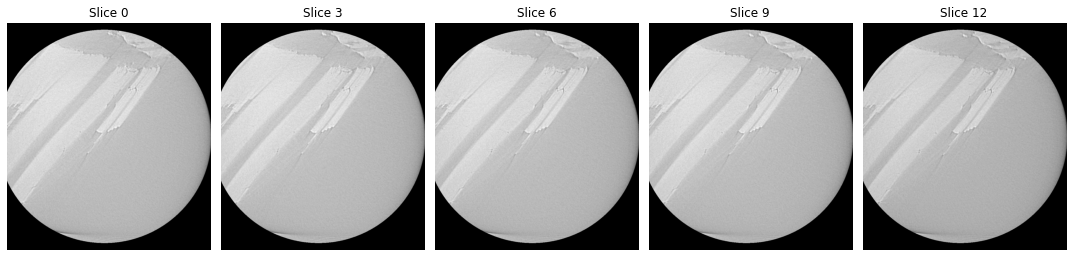

Visualizing preprocessed slices:


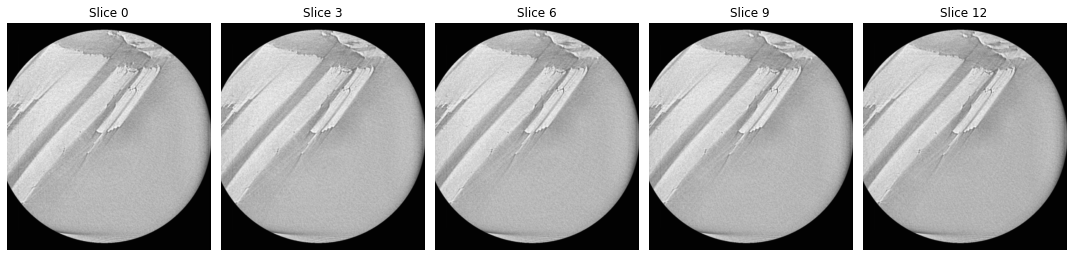

Visualizing 3D reconstruction:


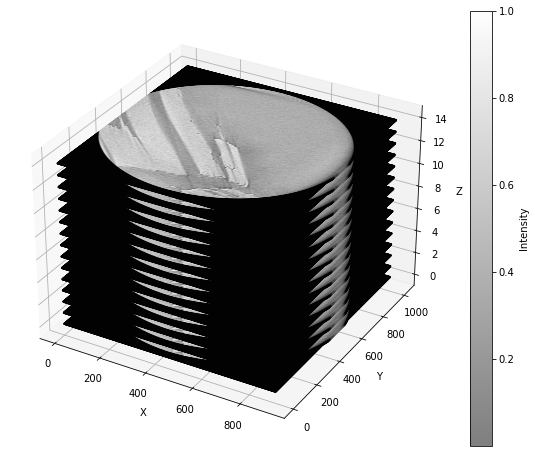

In [1]:
# Required Libraries
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.exposure import equalize_adapthist

# Step 1: Load TIFF Files
def load_tiff_stack(folder_path, num_files=None):
    """Load and stack TIFF files from a folder."""
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    if num_files:
        tiff_files = tiff_files[:num_files]
    image_stack = [tifffile.imread(file) for file in tiff_files]
    return np.stack(image_stack, axis=0)

# Step 2: Noise Reduction
def reduce_noise(image_stack, sigma=1):
    """Apply Gaussian filtering to reduce noise."""
    return gaussian_filter(image_stack, sigma=sigma)

# Step 3: Contrast Enhancement
def enhance_contrast(image_stack, clip_limit=0.01):
    """Apply CLAHE to enhance local contrast."""
    enhanced_stack = np.zeros_like(image_stack, dtype=np.float32)
    for i in range(image_stack.shape[0]):
        enhanced_stack[i] = equalize_adapthist(image_stack[i], clip_limit=clip_limit)
    return enhanced_stack

# Step 4: Normalize Intensities
def normalize_intensity(image_stack):
    """Normalize intensities to the range [0, 1]."""
    min_val = image_stack.min()
    max_val = image_stack.max()
    return (image_stack - min_val) / (max_val - min_val)

# Step 5: Visualize Slice
def visualize_slices(image_stack, num_slices=5):
    """Visualize a set of slices from the stack."""
    step = max(1, image_stack.shape[0] // num_slices)
    slices_to_show = range(0, image_stack.shape[0], step)
    
    fig, axes = plt.subplots(1, len(slices_to_show), figsize=(15, 5))
    for ax, idx in zip(axes, slices_to_show):
        ax.imshow(image_stack[idx], cmap='gray')
        ax.set_title(f"Slice {idx}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Step 6: 3D Visualization
def visualize_3d(image_stack):
    """Visualize the 3D stack with scatter plot."""
    z, y, x = np.nonzero(image_stack)
    intensities = image_stack[z, y, x]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(x, y, z, c=intensities, cmap='gist_gray', s=1, alpha=0.5)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    fig.colorbar(scatter, ax=ax, label='Intensity')
    plt.show()

# Paths
background_folder_path = "background_only"  # Background images
rock_folder_path = "sample_1_cs_4_2"  # Rock images

# Load Data
background_stack = load_tiff_stack(background_folder_path, num_files=10)
rock_stack = load_tiff_stack(rock_folder_path, num_files=15)

# Preprocessing Pipeline
# Step 1: Reduce Noise
rock_stack_denoised = reduce_noise(rock_stack, sigma=1)

# Step 2: Enhance Contrast
rock_stack_contrast = enhance_contrast(rock_stack_denoised, clip_limit=0.01)

# Step 3: Normalize Intensities
rock_stack_normalized = normalize_intensity(rock_stack_contrast)

# Visualization
print("Visualizing raw slices:")
visualize_slices(rock_stack)

print("Visualizing preprocessed slices:")
visualize_slices(rock_stack_normalized)

# 3D Visualization
print("Visualizing 3D reconstruction:")
visualize_3d(rock_stack_normalized)


## Attempt 3

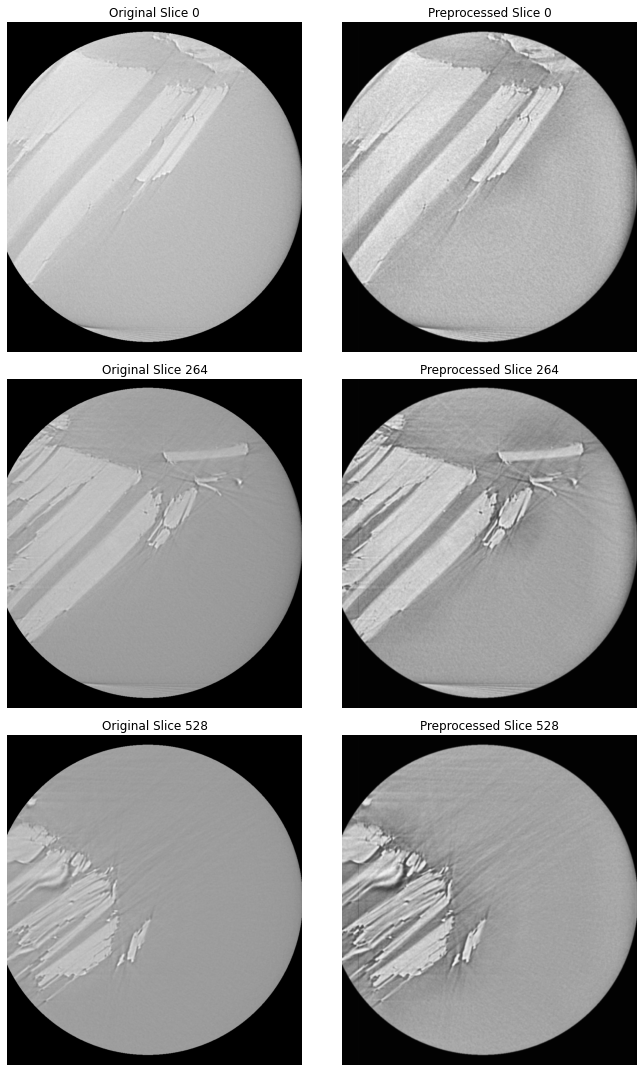

In [5]:
# Required Libraries
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.exposure import equalize_adapthist

# Step 1: Preprocess the TIFF files
def preprocess_images(folder_path, sigma=1, clip_limit=0.01):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    image_stack = [tifffile.imread(file) for file in tiff_files]
    image_stack = np.stack(image_stack, axis=0)
    
    # Apply noise reduction and contrast enhancement
    denoised_stack = gaussian_filter(image_stack, sigma=sigma)
    enhanced_stack = np.zeros_like(denoised_stack, dtype=np.float32)
    for i in range(denoised_stack.shape[0]):
        enhanced_stack[i] = equalize_adapthist(denoised_stack[i], clip_limit=clip_limit)
    return enhanced_stack

# Step 2: Compare Original TIFF Files with Preprocessed Images
def compare_original_and_preprocessed(original_folder, preprocessed_stack, num_slices=3):
    original_tiff_files = sorted([os.path.join(original_folder, f) for f in os.listdir(original_folder) if f.endswith('.tiff')])
    original_stack = [tifffile.imread(file) for file in original_tiff_files]
    original_stack = np.stack(original_stack, axis=0)

    step = max(1, original_stack.shape[0] // num_slices)
    slices_to_show = range(0, original_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(original_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Original Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Preprocessed Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Paths
background_folder_path = "background_only"  # Background TIFF files
rock_folder_path = "sample_1_cs_4_2"  # Rock sample TIFF files

# Step 1: Preprocess images from both folders
background_preprocessed = preprocess_images(background_folder_path, sigma=1, clip_limit=0.01)
rock_preprocessed = preprocess_images(rock_folder_path, sigma=1, clip_limit=0.01)

# Step 2: Compare original TIFF files with preprocessed images
compare_original_and_preprocessed(rock_folder_path, rock_preprocessed, num_slices=3)


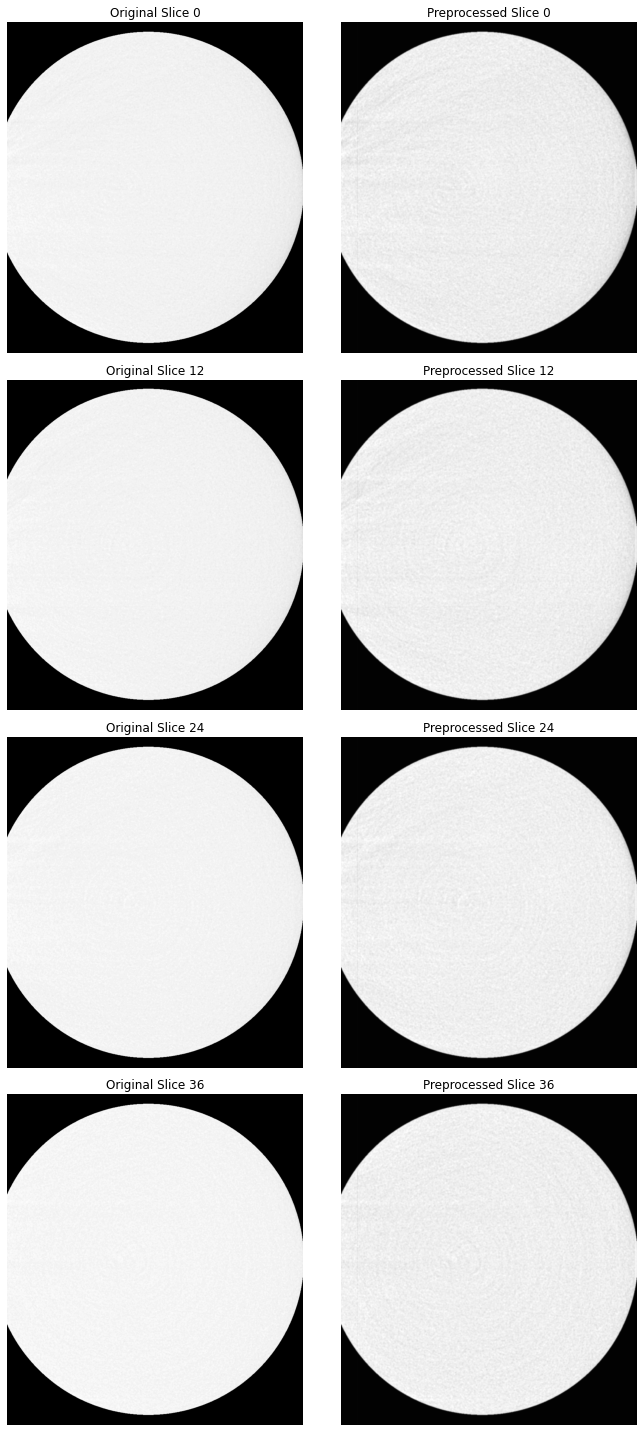

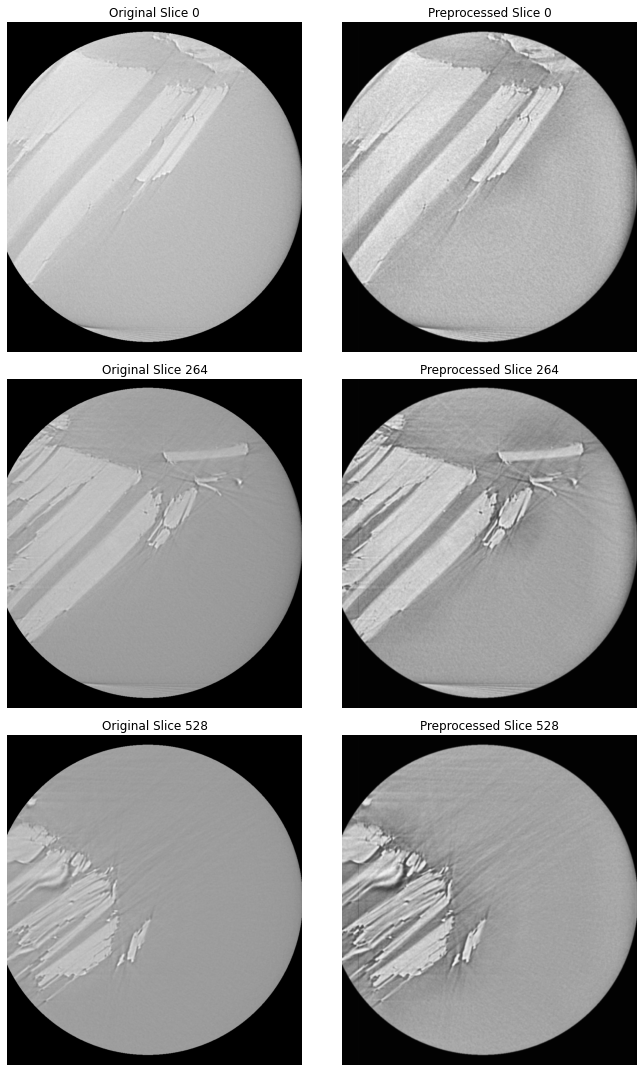

Background mean: 0.7113006711006165
Background tolerance interval: (0.4953006711006165, 0.9273006711006164)


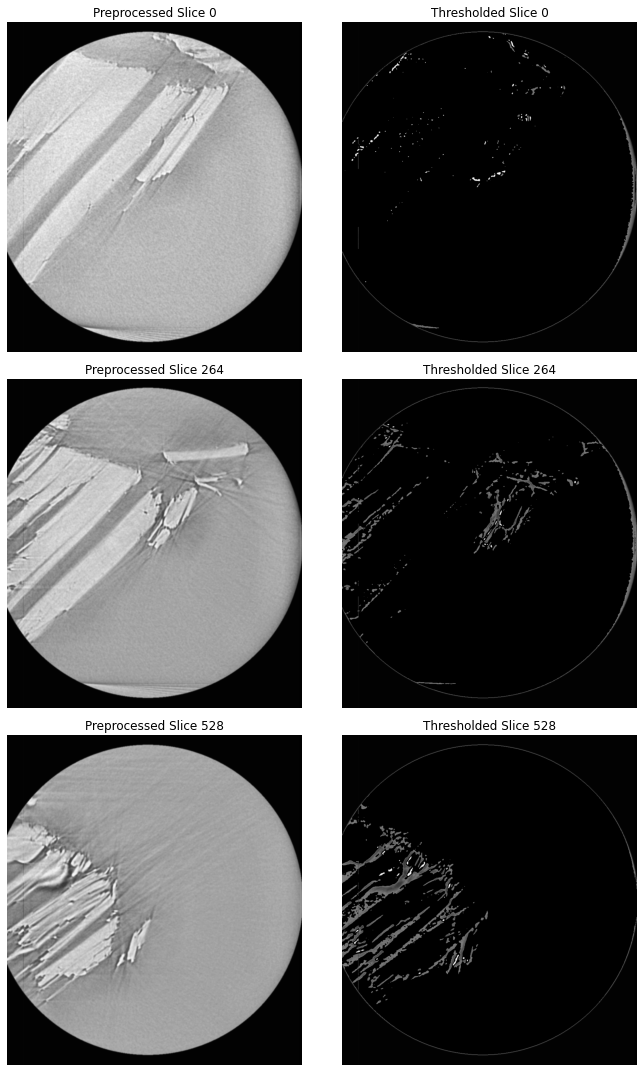

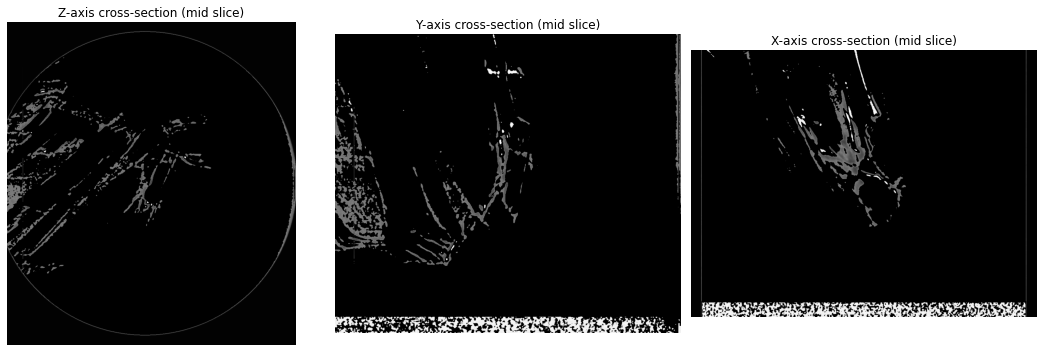

In [13]:
from scipy.ndimage import gaussian_filter
from skimage.exposure import equalize_adapthist

# Step 1: Preprocess the TIFF files
def preprocess_images(folder_path, sigma=1, clip_limit=0.01):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    image_stack = [tifffile.imread(file) for file in tiff_files]
    image_stack = np.stack(image_stack, axis=0)
    
    # Apply noise reduction and contrast enhancement
    denoised_stack = gaussian_filter(image_stack, sigma=sigma)
    enhanced_stack = np.zeros_like(denoised_stack, dtype=np.float32)
    for i in range(denoised_stack.shape[0]):
        enhanced_stack[i] = equalize_adapthist(denoised_stack[i], clip_limit=clip_limit)
    return enhanced_stack

# Step 2: Compare Original TIFF Files with Preprocessed Images
def compare_original_and_preprocessed(original_folder, preprocessed_stack, num_slices=3):
    original_tiff_files = sorted([os.path.join(original_folder, f) for f in os.listdir(original_folder) if f.endswith('.tiff')])
    original_stack = [tifffile.imread(file) for file in original_tiff_files]
    original_stack = np.stack(original_stack, axis=0)

    step = max(1, original_stack.shape[0] // num_slices)
    slices_to_show = range(0, original_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(original_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Original Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Preprocessed Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 3: Calculate background intensity tolerance range from preprocessed background images
def calculate_background_tolerance(background_stack, tolerance=3000):
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 4: Apply background tolerance filtering based on calculated tolerance interval
def apply_tolerance_filter(image_stack, tolerance_interval):
    filtered_stack = np.zeros_like(image_stack)
    lower, upper = tolerance_interval
    for i in range(image_stack.shape[0]):
        # Keep pixels that fall outside the tolerance interval
        filtered_stack[i] = np.where((image_stack[i] < lower) | (image_stack[i] > upper), image_stack[i], 0)
    return filtered_stack

# Step 5: Display comparison between preprocessed and thresholded images
def compare_preprocessed_and_thresholded(preprocessed_stack, thresholded_stack, num_slices=3):
    step = max(1, preprocessed_stack.shape[0] // num_slices)
    slices_to_show = range(0, preprocessed_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Preprocessed Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(thresholded_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Thresholded Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 6: Visualize 3D stack of thresholded slices
def visualize_3d_stack(filtered_stack):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    mid_z = filtered_stack.shape[0] // 2
    mid_y = filtered_stack.shape[1] // 2
    mid_x = filtered_stack.shape[2] // 2

    axes[0].imshow(filtered_stack[mid_z, :, :], cmap='gray')
    axes[0].set_title("Z-axis cross-section (mid slice)")

    axes[1].imshow(filtered_stack[:, mid_y, :], cmap='gray')
    axes[1].set_title("Y-axis cross-section (mid slice)")

    axes[2].imshow(filtered_stack[:, :, mid_x], cmap='gray')
    axes[2].set_title("X-axis cross-section (mid slice)")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Paths
background_folder_path = "background_only"
rock_folder_path = "sample_1_cs_4_2"  

# Step 1: Preprocess images from both folders
background_preprocessed = preprocess_images(background_folder_path, sigma=1, clip_limit=0.01)
rock_preprocessed = preprocess_images(rock_folder_path, sigma=1, clip_limit=0.01)

# Step 2: Compare original TIFF files with preprocessed images
compare_original_and_preprocessed(background_folder_path, background_preprocessed, num_slices=3)
compare_original_and_preprocessed(rock_folder_path, rock_preprocessed, num_slices=3)

# Step 3: Calculate the tolerance interval based on the preprocessed background
tolerance_interval = calculate_background_tolerance(background_preprocessed, tolerance=0.216)

# Step 4: Apply thresholding to the preprocessed rock images
thresholded_rock = apply_tolerance_filter(rock_preprocessed, tolerance_interval)

# Step 5: Compare preprocessed rock images with thresholded images
compare_preprocessed_and_thresholded(rock_preprocessed, thresholded_rock, num_slices=3)

# Step 6: Visualize the 3D stack of thresholded slices
visualize_3d_stack(thresholded_rock)


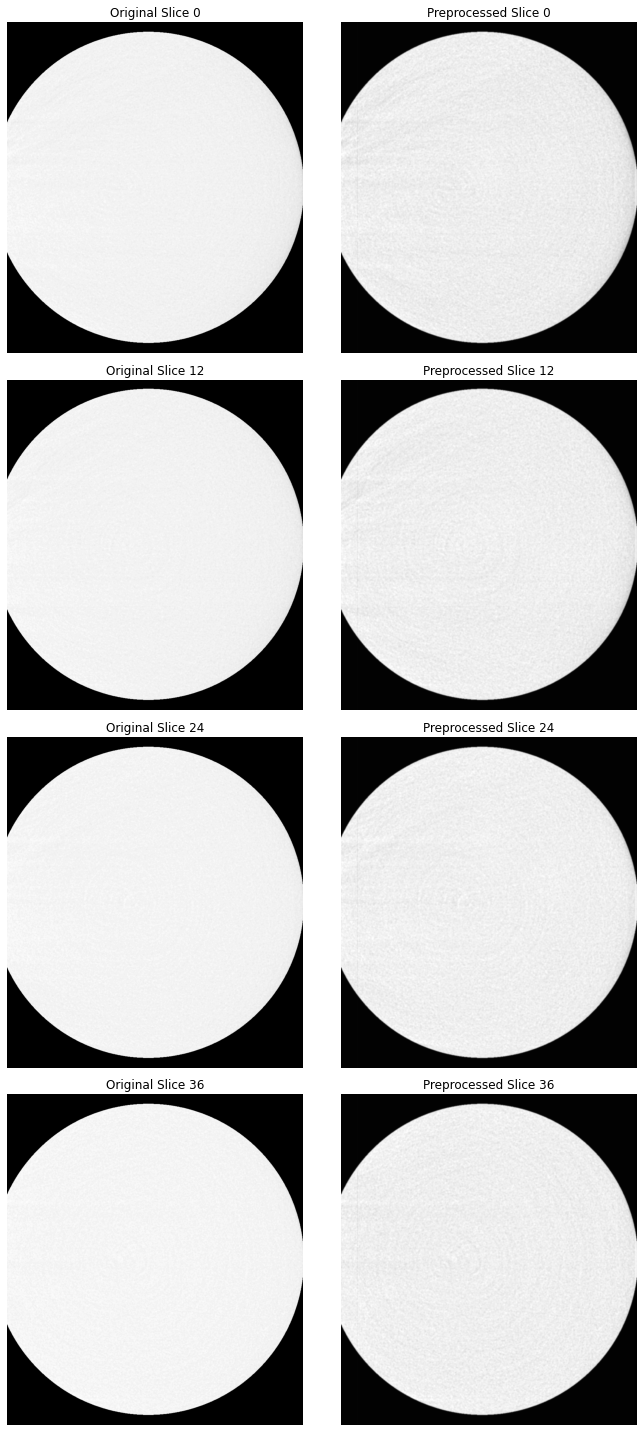

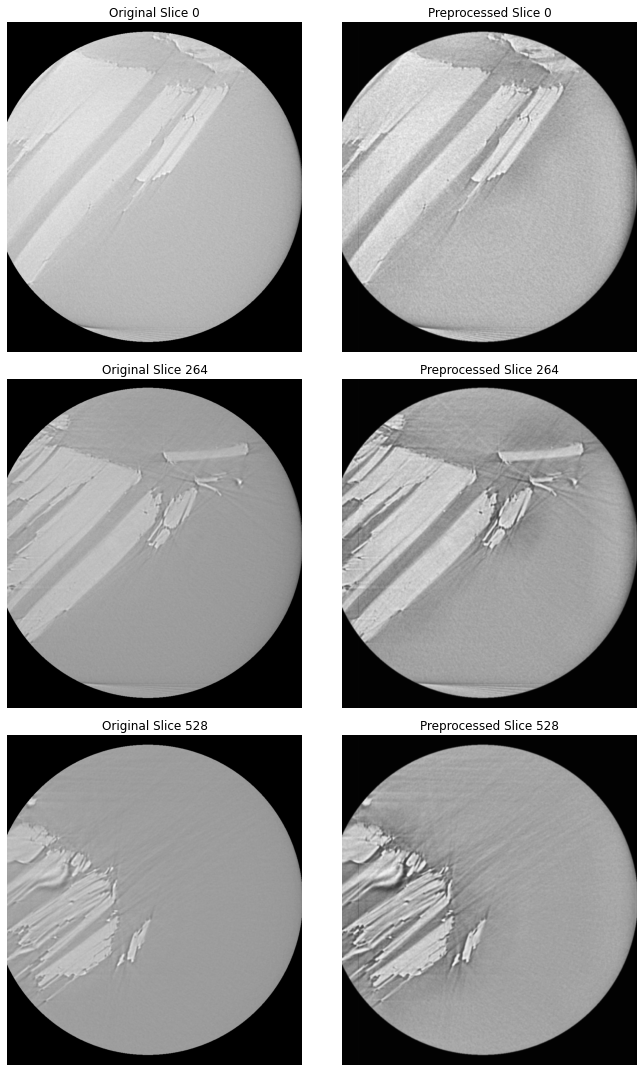

Background mean: 0.7113006711006165
Background tolerance interval: (0.6283006711006165, 0.7943006711006164)


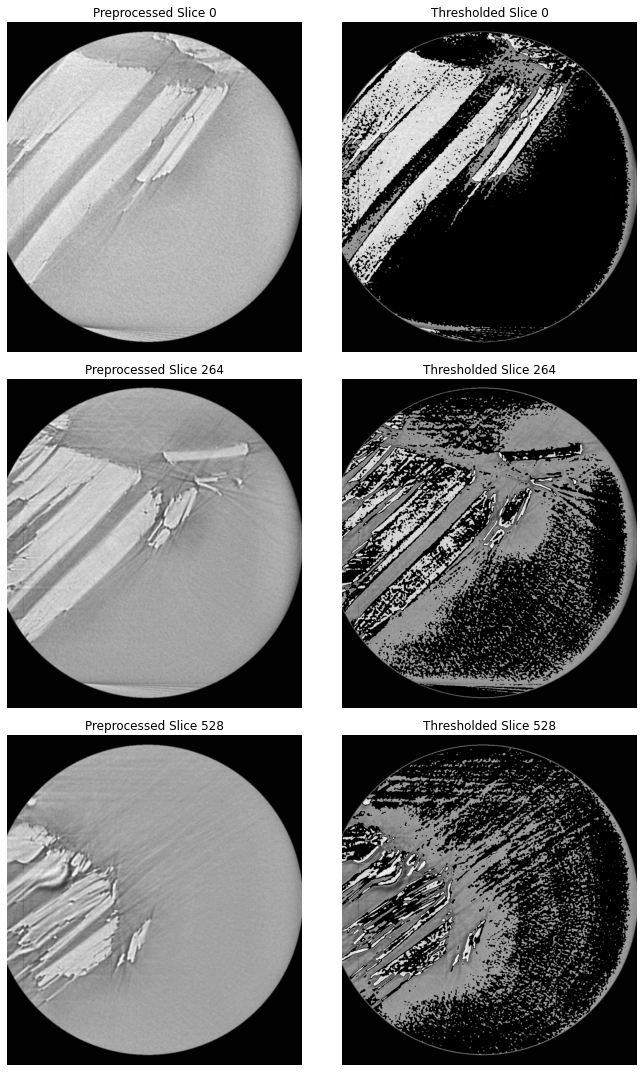

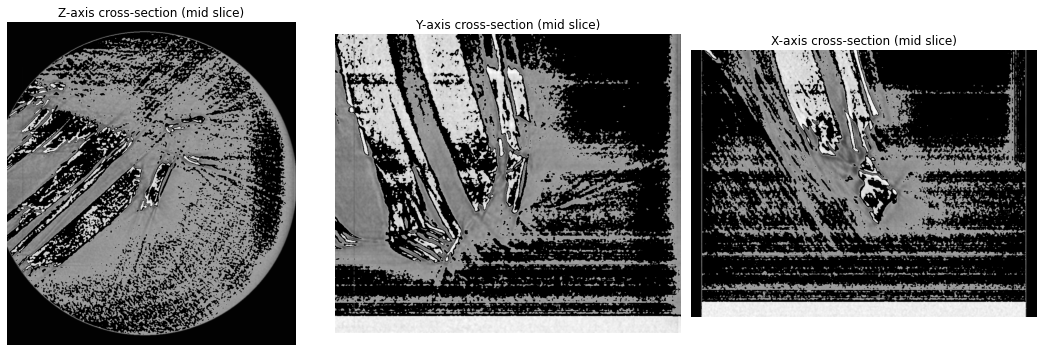

In [19]:
from scipy.ndimage import gaussian_filter
from skimage.exposure import equalize_adapthist

# Step 1: Preprocess the TIFF files
def preprocess_images(folder_path, sigma=1, clip_limit=0.01):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    image_stack = [tifffile.imread(file) for file in tiff_files]
    image_stack = np.stack(image_stack, axis=0)
    
    # Apply noise reduction and contrast enhancement
    denoised_stack = gaussian_filter(image_stack, sigma=sigma)
    enhanced_stack = np.zeros_like(denoised_stack, dtype=np.float32)
    for i in range(denoised_stack.shape[0]):
        enhanced_stack[i] = equalize_adapthist(denoised_stack[i], clip_limit=clip_limit)
    return enhanced_stack

# Step 2: Compare Original TIFF Files with Preprocessed Images
def compare_original_and_preprocessed(original_folder, preprocessed_stack, num_slices=3):
    original_tiff_files = sorted([os.path.join(original_folder, f) for f in os.listdir(original_folder) if f.endswith('.tiff')])
    original_stack = [tifffile.imread(file) for file in original_tiff_files]
    original_stack = np.stack(original_stack, axis=0)

    step = max(1, original_stack.shape[0] // num_slices)
    slices_to_show = range(0, original_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(original_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Original Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Preprocessed Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 3: Calculate background intensity tolerance range from preprocessed background images
def calculate_background_tolerance(background_stack, tolerance=0.1):
    """Calculate tolerance interval for normalized intensity range."""
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 4: Apply background tolerance filtering based on calculated tolerance interval
def apply_tolerance_filter(image_stack, tolerance_interval):
    filtered_stack = np.zeros_like(image_stack)
    lower, upper = tolerance_interval
    for i in range(image_stack.shape[0]):
        # Keep pixels that fall outside the tolerance interval
        filtered_stack[i] = np.where((image_stack[i] < lower) | (image_stack[i] > upper), image_stack[i], 0)
    return filtered_stack

# Step 5: Display comparison between preprocessed and thresholded images
def compare_preprocessed_and_thresholded(preprocessed_stack, thresholded_stack, num_slices=3):
    step = max(1, preprocessed_stack.shape[0] // num_slices)
    slices_to_show = range(0, preprocessed_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Preprocessed Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(thresholded_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Thresholded Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 6: Visualize 3D stack of thresholded slices
def visualize_3d_stack(filtered_stack):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    mid_z = filtered_stack.shape[0] // 2
    mid_y = filtered_stack.shape[1] // 2
    mid_x = filtered_stack.shape[2] // 2

    axes[0].imshow(filtered_stack[mid_z, :, :], cmap='gray')
    axes[0].set_title("Z-axis cross-section (mid slice)")

    axes[1].imshow(filtered_stack[:, mid_y, :], cmap='gray')
    axes[1].set_title("Y-axis cross-section (mid slice)")

    axes[2].imshow(filtered_stack[:, :, mid_x], cmap='gray')
    axes[2].set_title("X-axis cross-section (mid slice)")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Paths
background_folder_path = "background_only"  # Background TIFF files
rock_folder_path = "sample_1_cs_4_2"  # Rock sample TIFF files

# Step 1: Preprocess images from both folders
background_preprocessed = preprocess_images(background_folder_path, sigma=1, clip_limit=0.01)
rock_preprocessed = preprocess_images(rock_folder_path, sigma=1, clip_limit=0.01)

# Step 2: Compare original TIFF files with preprocessed images
compare_original_and_preprocessed(background_folder_path, background_preprocessed, num_slices=3)
compare_original_and_preprocessed(rock_folder_path, rock_preprocessed, num_slices=3)

# Step 3: Calculate the tolerance interval based on the preprocessed background
# Adjusted to normalized values
tolerance_interval = calculate_background_tolerance(background_preprocessed, tolerance=0.083)

# Step 4: Apply thresholding to the preprocessed rock images
thresholded_rock = apply_tolerance_filter(rock_preprocessed, tolerance_interval)

# Step 5: Compare preprocessed rock images with thresholded images
compare_preprocessed_and_thresholded(rock_preprocessed, thresholded_rock, num_slices=3)

# Step 6: Visualize the 3D stack of thresholded slices
visualize_3d_stack(thresholded_rock)


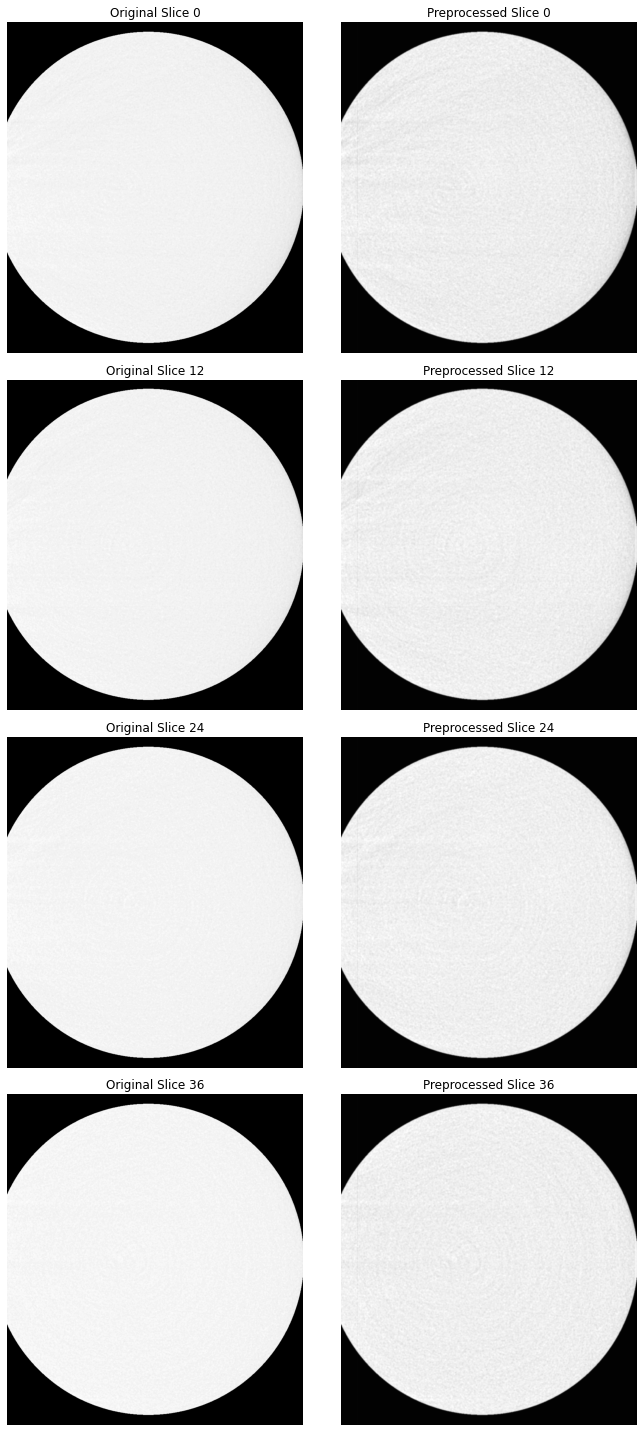

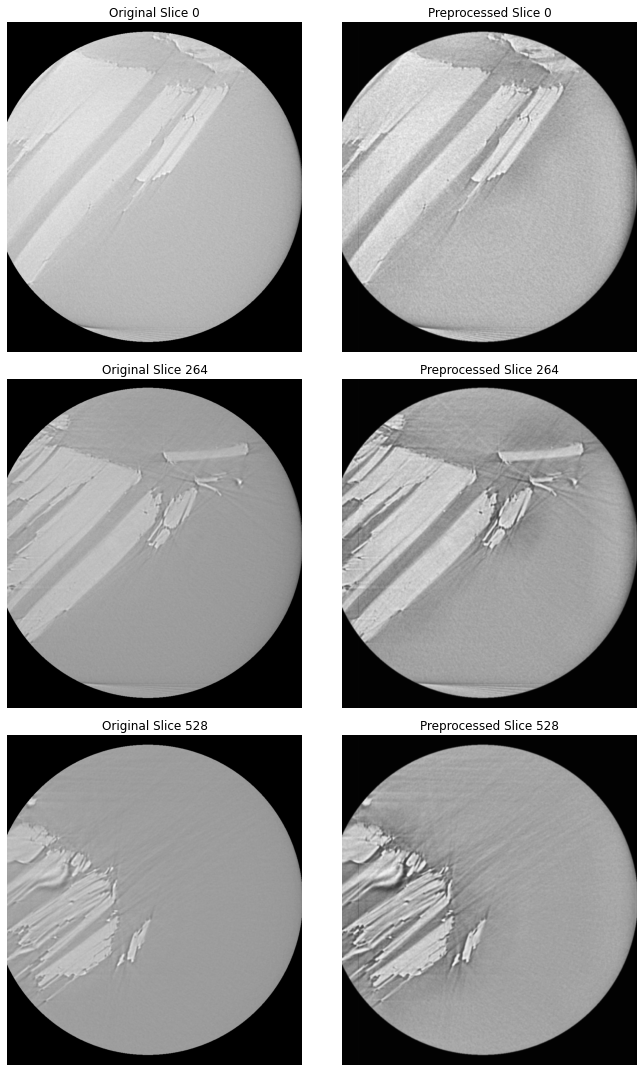

Background mean: 0.7113006711006165
Background tolerance interval: (0.6113006711006165, 0.8113006711006164)


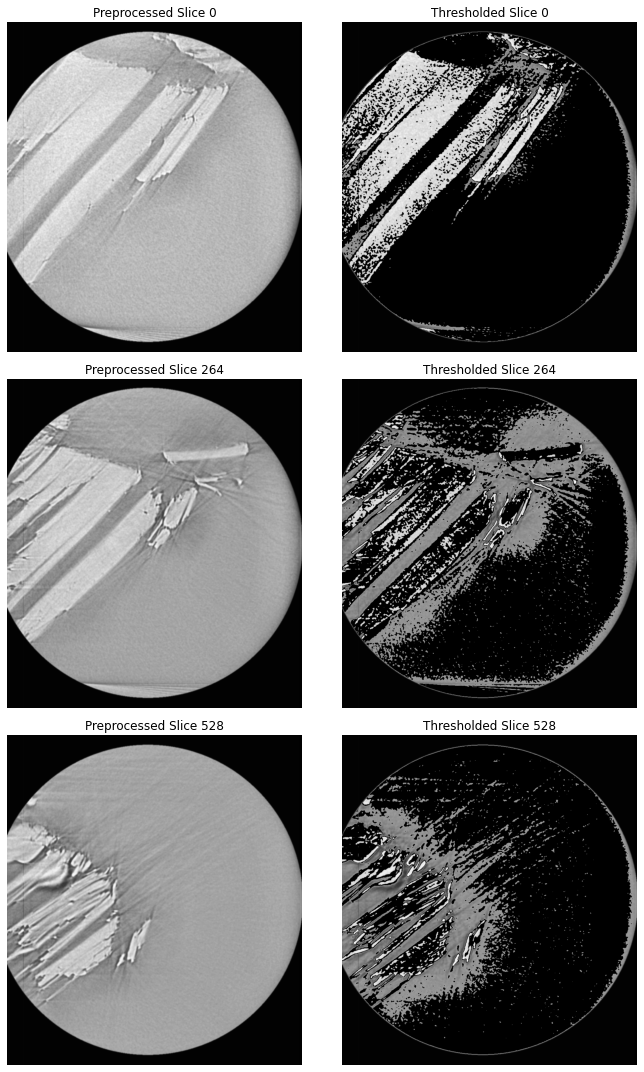

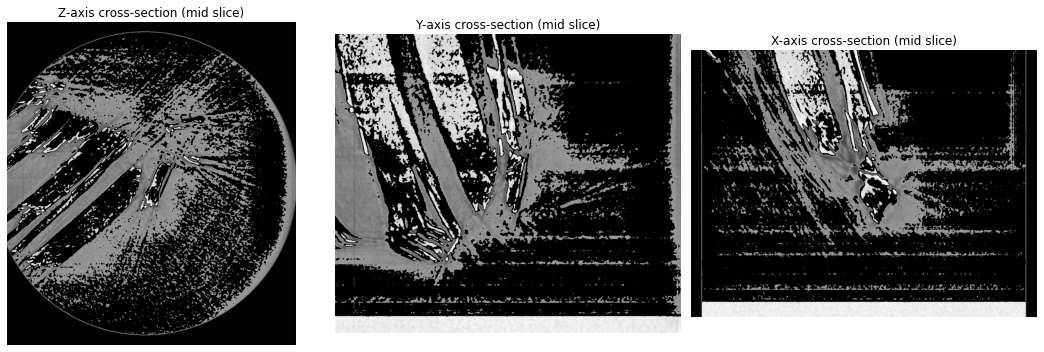

KeyboardInterrupt: 

In [25]:
from scipy.ndimage import gaussian_filter
from skimage.exposure import equalize_adapthist

# Step 1: Preprocess the TIFF files
def preprocess_images(folder_path, sigma=1, clip_limit=0.01):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    image_stack = [tifffile.imread(file) for file in tiff_files]
    image_stack = np.stack(image_stack, axis=0)
    
    # Apply noise reduction and contrast enhancement
    denoised_stack = gaussian_filter(image_stack, sigma=sigma)
    enhanced_stack = np.zeros_like(denoised_stack, dtype=np.float32)
    for i in range(denoised_stack.shape[0]):
        enhanced_stack[i] = equalize_adapthist(denoised_stack[i], clip_limit=clip_limit)
    return enhanced_stack

# Step 2: Compare Original TIFF Files with Preprocessed Images
def compare_original_and_preprocessed(original_folder, preprocessed_stack, num_slices=3):
    original_tiff_files = sorted([os.path.join(original_folder, f) for f in os.listdir(original_folder) if f.endswith('.tiff')])
    original_stack = [tifffile.imread(file) for file in original_tiff_files]
    original_stack = np.stack(original_stack, axis=0)

    step = max(1, original_stack.shape[0] // num_slices)
    slices_to_show = range(0, original_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(original_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Original Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Preprocessed Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 3: Calculate background intensity tolerance range from preprocessed background images
def calculate_background_tolerance(background_stack, tolerance=0.1):
    """Calculate tolerance interval for normalized intensity range."""
    background_mean = background_stack.mean()
    lower_bound = background_mean - tolerance
    upper_bound = background_mean + tolerance
    print(f"Background mean: {background_mean}")
    print(f"Background tolerance interval: ({lower_bound}, {upper_bound})")
    return (lower_bound, upper_bound)

# Step 4: Apply background tolerance filtering based on calculated tolerance interval
def apply_tolerance_filter(image_stack, tolerance_interval):
    filtered_stack = np.zeros_like(image_stack)
    lower, upper = tolerance_interval
    for i in range(image_stack.shape[0]):
        # Keep pixels that fall outside the tolerance interval
        filtered_stack[i] = np.where((image_stack[i] < lower) | (image_stack[i] > upper), image_stack[i], 0)
    return filtered_stack

# Step 5: Display comparison between preprocessed and thresholded images
def compare_preprocessed_and_thresholded(preprocessed_stack, thresholded_stack, num_slices=3):
    step = max(1, preprocessed_stack.shape[0] // num_slices)
    slices_to_show = range(0, preprocessed_stack.shape[0], step)

    fig, axes = plt.subplots(len(slices_to_show), 2, figsize=(10, 5 * len(slices_to_show)))
    for i, idx in enumerate(slices_to_show):
        axes[i, 0].imshow(preprocessed_stack[idx], cmap='gray')
        axes[i, 0].set_title(f"Preprocessed Slice {idx}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(thresholded_stack[idx], cmap='gray')
        axes[i, 1].set_title(f"Thresholded Slice {idx}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Step 6: Visualize 3D stack of thresholded slices
def visualize_3d_stack(filtered_stack):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    mid_z = filtered_stack.shape[0] // 2
    mid_y = filtered_stack.shape[1] // 2
    mid_x = filtered_stack.shape[2] // 2

    axes[0].imshow(filtered_stack[mid_z, :, :], cmap='gray')
    axes[0].set_title("Z-axis cross-section (mid slice)")

    axes[1].imshow(filtered_stack[:, mid_y, :], cmap='gray')
    axes[1].set_title("Y-axis cross-section (mid slice)")

    axes[2].imshow(filtered_stack[:, :, mid_x], cmap='gray')
    axes[2].set_title("X-axis cross-section (mid slice)")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Paths
background_folder_path = "background_only"  # Background TIFF files
rock_folder_path = "sample_1_cs_4_2"  # Rock sample TIFF files

# Step 1: Preprocess images from both folders
background_preprocessed = preprocess_images(background_folder_path, sigma=1, clip_limit=0.01)
rock_preprocessed = preprocess_images(rock_folder_path, sigma=1, clip_limit=0.01)

# Step 2: Compare original TIFF files with preprocessed images
compare_original_and_preprocessed(background_folder_path, background_preprocessed, num_slices=3)
compare_original_and_preprocessed(rock_folder_path, rock_preprocessed, num_slices=3)

# Step 3: Calculate the tolerance interval based on the preprocessed background
# Adjusted to normalized values
tolerance_interval = calculate_background_tolerance(background_preprocessed, tolerance=0.1)

# Step 4: Apply thresholding to the preprocessed rock images
thresholded_rock = apply_tolerance_filter(rock_preprocessed, tolerance_interval)

# Step 5: Compare preprocessed rock images with thresholded images
compare_preprocessed_and_thresholded(rock_preprocessed, thresholded_rock, num_slices=3)

# Step 6: Visualize the 3D stack of thresholded slices
visualize_3d_stack(thresholded_rock)
# Additional Block: Render 3D Plot from Preprocessed Thresholded Files

def plot_3d_intensity_thresholded(preprocessed_thresholded_stack):
    """Render a 3D scatter plot from the preprocessed and thresholded TIFF stack."""
    # Extract non-zero coordinates and their intensities
    z, y, x = np.nonzero(preprocessed_thresholded_stack)
    intensities = preprocessed_thresholded_stack[z, y, x]

    # Create a 3D scatter plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(x, y, z, c=intensities, cmap='gist_yarg', s=1, alpha=0.5)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    fig.colorbar(scatter, ax=ax, label='Intensity')
    plt.show()

# Apply the function on all preprocessed and thresholded files
plot_3d_intensity_thresholded(thresholded_rock)


## Attempt 4

In [1]:
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects

def load_tiff_stack(folder_path):
    tiff_files = sorted([os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tiff')])
    images = [tifffile.imread(file) for file in tiff_files]
    return np.stack(images, axis=0)

def apply_otsu_thresholding(image_stack):
    flattened = image_stack.flatten()
    thresh = threshold_otsu(flattened)
    print(f"Otsu's threshold: {thresh}")
    binary_stack = image_stack > thresh
    return binary_stack

def remove_noise(binary_stack, min_size=100):
    denoised_stack = np.zeros_like(binary_stack)
    for i in range(binary_stack.shape[0]):
        denoised_slice = remove_small_objects(binary_stack[i], min_size=min_size)
        denoised_stack[i] = denoised_slice
    return denoised_stack

def visualize_volume(binary_stack):
    import pyvista as pv
    pv.start_xvfb()  # Starts a virtual display if needed
    grid = pv.wrap(binary_stack)
    grid = grid.threshold(0.5)
    p = pv.Plotter()
    p.add_volume(grid, cmap="gray")
    p.show()

# Main Script
rock_folder_path = "sample_1_cs_4_2"
image_stack = load_tiff_stack(rock_folder_path)
binary_stack = apply_otsu_thresholding(image_stack)
denoised_stack = remove_noise(binary_stack)
visualize_volume(denoised_stack)


Otsu's threshold: 18878


TypeError: Type <class 'pyvista.core.pointset.UnstructuredGrid'> not supported for volume rendering at this time. Use `pyvista.UniformGrid`.

----------------------------------------------------

In [2]:
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects
from scipy.ndimage import median_filter
import pyvista as pv

# Start virtual framebuffer if needed (useful if running on a headless server)
# pv.start_xvfb()


In [16]:
def load_tiff_stack(folder_path):
    tiff_files = sorted([os.path.join(folder_path, f)
                         for f in os.listdir(folder_path)
                         if f.lower().endswith(('.tiff', '.tif'))])
    images = [tifffile.imread(file) for file in tiff_files]
    image_stack = np.stack(images, axis=0)
    return image_stack

def denoise_image_stack(image_stack, size=3):
    denoised_stack = median_filter(image_stack, size=(1, size, size))
    return denoised_stack

def apply_otsu_thresholding(image_stack):
    # Flatten the image stack to compute a global threshold
    flattened = image_stack.flatten()
    thresh = threshold_otsu(flattened)
    print(f"Otsu's threshold: {thresh}")
    # Apply the threshold to create a binary image stack
    binary_stack = image_stack > thresh
    return binary_stack

def remove_noise(binary_stack, min_size=100):
    denoised_stack = np.zeros_like(binary_stack, dtype=bool)
    for i in range(binary_stack.shape[0]):
        denoised_slice = remove_small_objects(binary_stack[i], min_size=min_size)
        denoised_stack[i] = denoised_slice
    return denoised_stack

def visualize_volume(binary_stack):
    # Ensure the data is in the correct format
    volume = binary_stack.astype(np.uint8)

    # Transpose the volume to (x, y, z) order
    volume = volume.transpose(2, 1, 0)

    # Create a PyVista UniformGrid directly from the numpy array
    grid = pv.wrap(volume)

    # Initialize the plotter
    p = pv.Plotter()

    # Add the volume data to the plotter
    p.add_volume(grid, cmap="gray", opacity=[0, 1])

    # Show the axes with default labels
    p.show_axes()

    # Optionally, customize the axes labels
    # Access the axes actor
    axes_actor = p.renderer.axes_actor

    # Set the labels
    axes_actor.SetXAxisLabelText('X')
    axes_actor.SetYAxisLabelText('Y')
    axes_actor.SetZAxisLabelText('Z')

    # Adjust the font size (optional)
    axes_actor.GetXAxisCaptionActor2D().GetCaptionTextProperty().SetFontSize(14)
    axes_actor.GetYAxisCaptionActor2D().GetCaptionTextProperty().SetFontSize(14)
    axes_actor.GetZAxisCaptionActor2D().GetCaptionTextProperty().SetFontSize(14)

    # Show the plot
    print("Rendering the 3D volume...")
    p.show()




In [4]:
# The path to rock images folder
rock_folder_path = "sample_1_cs_4_2"  

# Load the images into a stack
print("Loading images...")
image_stack = load_tiff_stack(rock_folder_path)
print(f"Loaded {image_stack.shape[0]} images with shape {image_stack.shape[1:]} each.")


Loading images...
Loaded 792 images with shape (1024, 916) each.


In [5]:
# Apply noise reduction to the image stack
print("Applying noise reduction...")
denoised_stack = denoise_image_stack(image_stack, size=3)


Applying noise reduction...


In [6]:
# Apply Otsu's thresholding to the denoised image stack
print("Applying Otsu's thresholding...")
binary_stack = apply_otsu_thresholding(denoised_stack)


Applying Otsu's thresholding...
Otsu's threshold: 18878


In [7]:
# Remove small objects from the binary image stack
print("Removing small objects...")
cleaned_stack = remove_noise(binary_stack, min_size=100)


Removing small objects...


In [17]:
# Visualize the 3D volume
visualize_volume(cleaned_stack)


Rendering the 3D volume...


2024-11-22 14:10:53.713 (1248.399s) [        44AC3740]   vtkVolumeTexture.cxx:739    ERR| vtkVolumeTexture (0x98ff6d0): Capabilities check via proxy texture 3D allocation failed!
ERROR:root:Capabilities check via proxy texture 3D allocation failed!


ViewInteractiveWidget(height=768, layout=Layout(height='auto', width='100%'), width=1024)

In [18]:
import shutil

# Specify the folder to compress and the output ZIP file name
folder_to_zip = "thresholded_samples" 
output_zip_file = "thresholded_samples.zip"

# Compress the folder
shutil.make_archive(base_name=output_zip_file.replace('.zip', ''), format='zip', root_dir=folder_to_zip)

print(f"Folder compressed to {output_zip_file}")


Folder compressed to thresholded_samples.zip
